In [3]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics

### Importing Required Libraries

In this step, we imported the Python libraries required to build and evaluate the Decision Tree classification model.

* **Pandas (`pd`):** Used to load and organize the dataset.
* **DecisionTreeClassifier:** Used to create and train the Decision Tree model using Gini Index and Entropy.
* **train_test_split:** Used to divide the dataset into training and testing sets.
* **metrics:** Used to evaluate the model's performance by calculating accuracy and the confusion matrix.

These libraries will be used throughout the classification process.


In [4]:
#Loading Data

df = pd.read_csv(
    "https://raw.githubusercontent.com/Ghhaidaa/Data-Mining-Project-/main/Dataset/Preprocessed_dataset.csv"
)

print(df.head())

   student_id  gender  study_time_hours  attendance_percent  sleep_hours  \
0           1    Male          0.460526            0.955752     0.485294   
1           2  Female          0.763158            1.000000     0.367647   
2           3    Male          0.578947            0.674779     0.691176   
3           4    Male          0.276316            0.502212     0.705882   
4           5    Male          0.223684            0.769912     0.205882   

  parental_education internet_access extracurricular_activities part_time_job  \
0          Bachelors             Yes                        Yes            No   
1        High School             Yes                        Yes           Yes   
2          Bachelors             Yes                         No           Yes   
3        High School             Yes                        Yes            No   
4          Bachelors             Yes                         No           Yes   

   previous_grade  final_exam_score final_grade study_ti

### Loading Data

We loaded the preprocessed student dataset (`Preprocessed_dataset.csv`) using `pd.read_csv()`.

The dataset was stored in a DataFrame named `df`, and `df.head()` was used to display the first five rows and verify that the data was loaded successfully.

We used the preprocessed dataset from Phase 2 because the data had already been prepared for the data mining tasks.


# 1. Problem


# 2. Data Mining Task


# 3. Data

# 4. Data Preprocessing

# 5. Data Mining Technique

## 5.1 Classification – Decision Tree


In [ ]:
#Feature Selection

X = df.drop(columns=['student_id', 'final_grade', 'final_exam_score'])
y = df['final_grade']

print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['gender', 'study_time_hours', 'attendance_percent', 'sleep_hours', 'parental_education', 'internet_access', 'extracurricular_activities', 'part_time_job', 'previous_grade', 'study_time_category']
Target: final_grade


### Feature Selection

In this step, we selected the input features (X) and the target variable (y) for the Decision Tree classification.

The target variable is `final_grade`, which represents the student's final grade category.

We excluded `student_id` because it is only an identifier. We also excluded `final_exam_score` to avoid potential target leakage, since the final grade may be directly related to the exam score.

The remaining attributes were selected as input features to predict students' final grades.



In [ ]:
#Encoding Categorical Features

X = pd.get_dummies(X, dtype=int)

print("Features shape:", X.shape)
print(X.head())

Features shape: (1000, 19)
   study_time_hours  attendance_percent  sleep_hours  previous_grade  \
0          0.460526            0.955752     0.485294        0.663755   
1          0.763158            1.000000     0.367647        0.643377   
2          0.578947            0.674779     0.691176        0.832606   
3          0.276316            0.502212     0.705882        0.783115   
4          0.223684            0.769912     0.205882        0.443959   

   gender_Female  gender_Male  parental_education_Bachelors  \
0              0            1                             1   
1              1            0                             0   
2              0            1                             1   
3              0            1                             0   
4              0            1                             1   

   parental_education_High School  parental_education_Masters  \
0                               0                           0   
1                              

### Encoding Categorical Features

Before training the Decision Tree model, we converted the categorical input features into numerical values using `pd.get_dummies()`.

This step was necessary because the Decision Tree classifier in Scikit-learn requires numerical input features.

The `dtype=int` parameter was used to represent the encoded categories as 0 and 1. We then displayed the shape and first five rows of the transformed dataset to verify the result.

The target variable, `final_grade`, was kept unchanged because it represents the class labels we want to predict.


In [ ]:
#Splitting Data

splits = {}

for test_size in [0.10, 0.20, 0.30]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42
    )

    splits[test_size] = (X_train, X_test, y_train, y_test)

    print("Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Training samples:", len(X_train))
    print("Testing samples:", len(X_test))
    print("--------------------")

Training: 90 %
Testing: 10 %
Training samples: 900
Testing samples: 100
--------------------
Training: 80 %
Testing: 20 %
Training samples: 800
Testing samples: 200
--------------------
Training: 70 %
Testing: 30 %
Training samples: 700
Testing samples: 300
--------------------


### Splitting Data

In this step, we used `train_test_split()` to divide the dataset into training and testing sets.

We applied three different partitions: **90% training / 10% testing**, **80% training / 20% testing**, and **70% training / 30% testing**, as required in Phase 3.

The training set is used to build the Decision Tree model, while the testing set is used to evaluate its accuracy on unseen data.

We used `random_state=42` to make the results reproducible. Each partition was stored in the `splits` dictionary so it could be used later to train and test the Gini and Entropy models.

Using these three partitions allows us to compare the classification results with different amounts of training and testing data.


In [ ]:
#Decision Tree Using Gini Index

gini_models = {}

for test_size in [0.10, 0.20, 0.30]:

    X_train, X_test, y_train, y_test = splits[test_size]

    clf = DecisionTreeClassifier(criterion='gini', random_state=42)

    clf.fit(X_train, y_train)

    gini_models[test_size] = clf

    y_pred = clf.predict(X_test)

    print("Gini - Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Model trained successfully")
    print("--------------------")

Gini - Training: 90 %
Testing: 10 %
Model trained successfully
--------------------
Gini - Training: 80 %
Testing: 20 %
Model trained successfully
--------------------
Gini - Training: 70 %
Testing: 30 %
Model trained successfully
--------------------


### Decision Tree Using Gini Index

In this step, we built Decision Tree classification models using the **Gini Index** as the splitting criterion.

We used `DecisionTreeClassifier(criterion='gini')` to create the models and applied them to the three training/testing partitions: 90/10, 80/20, and 70/30.

For each partition, the `fit()` method trained the model using the training data, while `predict()` generated predictions for the testing data.

The trained models were stored in the `gini_models` dictionary so they could be used later for evaluation and visualization.

The Gini Index measures the impurity of the data and helps the Decision Tree select suitable splits.

The accuracy and confusion matrices will be calculated in the evaluation section to assess the performance of each model.


In [ ]:
#Decision Tree Using Entropy (Information Gain)

entropy_models = {}

for test_size in [0.10, 0.20, 0.30]:

    X_train, X_test, y_train, y_test = splits[test_size]

    clf = DecisionTreeClassifier(criterion='entropy', random_state=42)

    clf.fit(X_train, y_train)

    entropy_models[test_size] = clf

    y_pred = clf.predict(X_test)

    print("Entropy - Training:", int((1 - test_size) * 100), "%")
    print("Testing:", int(test_size * 100), "%")
    print("Model trained successfully")
    print("--------------------")

Entropy - Training: 90 %
Testing: 10 %
Model trained successfully
--------------------
Entropy - Training: 80 %
Testing: 20 %
Model trained successfully
--------------------
Entropy - Training: 70 %
Testing: 30 %
Model trained successfully
--------------------


### Decision Tree Using Entropy (Information Gain)

In this step, we built three Decision Tree classification models using **Entropy (Information Gain)** as the splitting criterion.

We used `DecisionTreeClassifier(criterion='entropy')` and applied it to the same training/testing partitions used for Gini: 90/10, 80/20, and 70/30.

For each partition, the `fit()` method was used to train the model, while `predict()` was used to predict students' final grades.

The trained models were stored in the `entropy_models` dictionary for later evaluation and visualization.

Entropy measures the uncertainty in the class distribution, while Information Gain helps the Decision Tree select splits that reduce this uncertainty.

Using the same partitions for both Gini and Entropy allows us to compare their classification performance under consistent conditions.


# 6. Evaluation and Comparison

## 6.1 Classification – Evaluation

In [ ]:
#Accuracy Evaluation

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]

        y_pred = clf.predict(X_test)

        accuracy = metrics.accuracy_score(y_test, y_pred)

        print("Criterion:", criterion)
        print("Training:", int((1 - test_size) * 100), "%")
        print("Testing:", int(test_size * 100), "%")
        print("Accuracy:", round(accuracy * 100, 2), "%")
        print("--------------------")

Criterion: Gini
Training: 90 %
Testing: 10 %
Accuracy: 42.0 %
--------------------
Criterion: Gini
Training: 80 %
Testing: 20 %
Accuracy: 43.5 %
--------------------
Criterion: Gini
Training: 70 %
Testing: 30 %
Accuracy: 45.67 %
--------------------
Criterion: Entropy
Training: 90 %
Testing: 10 %
Accuracy: 44.0 %
--------------------
Criterion: Entropy
Training: 80 %
Testing: 20 %
Accuracy: 42.5 %
--------------------
Criterion: Entropy
Training: 70 %
Testing: 30 %
Accuracy: 43.0 %
--------------------


### Accuracy Evaluation

In this step, we evaluated the performance of the Decision Tree models using `metrics.accuracy_score()`, as demonstrated in the classification lab.

For each model, we used `predict()` to predict students' final grades from the testing data. We then compared the predicted grades with the actual grades to calculate the classification accuracy.

We evaluated both Gini and Entropy using three training/testing partitions: 90/10, 80/20, and 70/30, resulting in six accuracy values.

Accuracy represents the percentage of students whose final grades were predicted correctly. These results will be used to compare the performance of the two splitting criteria.


### Accuracy Results

The Decision Tree models were evaluated using three training/testing partitions and two splitting criteria: Gini Index and Entropy.

**Gini Index Results:**

* **90/10:** The model achieved 42% accuracy, correctly predicting 42 out of 100 students.
* **80/20:** The model achieved 43.5% accuracy, correctly predicting 87 out of 200 students.
* **70/30:** The model achieved 45.67% accuracy, correctly predicting 137 out of 300 students.

**Entropy Results:**

* **90/10:** The model achieved 44% accuracy, correctly predicting 44 out of 100 students.
* **80/20:** The model achieved 42.5% accuracy, correctly predicting 85 out of 200 students.
* **70/30:** The model achieved 43% accuracy, correctly predicting 129 out of 300 students.

**Results Comparison:**

For the 90/10 partition, Entropy achieved higher accuracy than Gini by 2 percentage points.

For the 80/20 partition, Gini achieved higher accuracy than Entropy by 1 percentage point.

For the 70/30 partition, Gini achieved higher accuracy than Entropy by approximately 2.67 percentage points.

The highest accuracy was **45.67%**, achieved using Gini Index with the 70/30 partition.

However, all six models achieved accuracy below 50%, indicating that the models made more incorrect predictions than correct predictions on their respective testing sets.

These results show that both the splitting criterion and the training/testing partition affected the observed classification accuracy.


In [ ]:
# Accuracy Comparison Table

results = []

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    row = {'Criterion': criterion}

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]
        y_pred = clf.predict(X_test)

        accuracy = metrics.accuracy_score(y_test, y_pred)

        partition = f"{int((1-test_size)*100)}/{int(test_size*100)}"
        row[partition] = round(accuracy * 100, 2)

    results.append(row)

comparison_table = pd.DataFrame(results)
print(comparison_table)

  Criterion  90/10  80/20  70/30
0      Gini   42.0   43.5  45.67
1   Entropy   44.0   42.5  43.00


### Accuracy Comparison Table

The table summarizes the classification accuracy of the Decision Tree models using Gini Index and Entropy across the three training/testing partitions.

We calculated the accuracy using `metrics.accuracy_score()` and organized the results into a table using Pandas.

For the 90/10 partition, Entropy achieved higher accuracy (44%) than Gini (42%). However, Gini performed better in the 80/20 and 70/30 partitions.

The highest accuracy was **45.67%**, achieved by Gini using the 70/30 partition.

This table provides a clear comparison of the six experiments and shows how the accuracy varied across the two splitting criteria and three partitions.


Criterion: Gini
Training: 90 %
Testing: 10 %
Confusion Matrix:
[[11  9  0  0  0]
 [ 8 20 10  1  0]
 [ 4  9 10  4  0]
 [ 0  7  4  1  1]
 [ 0  1  0  0  0]]


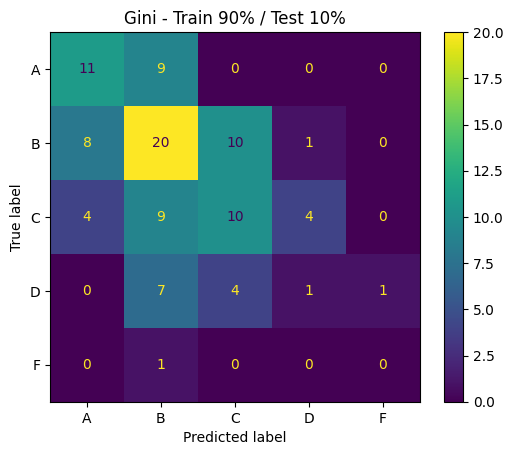

Criterion: Gini
Training: 80 %
Testing: 20 %
Confusion Matrix:
[[30 14  2  1  0]
 [19 30 15  9  0]
 [ 3 21 22  8  1]
 [ 0 11  6  5  1]
 [ 0  1  1  0  0]]


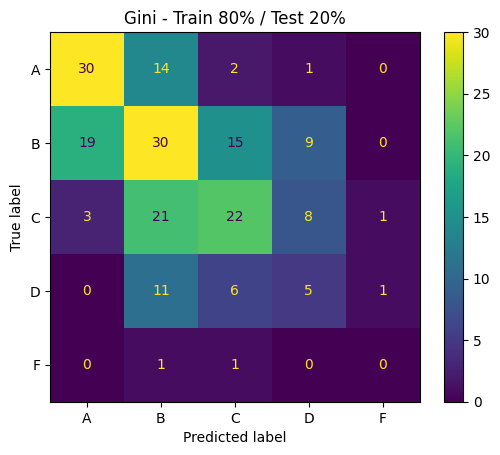

Criterion: Gini
Training: 70 %
Testing: 30 %
Confusion Matrix:
[[45 25  6  0  1]
 [31 51 17  5  0]
 [11 28 35  8  1]
 [ 1 10 16  6  1]
 [ 0  0  2  0  0]]


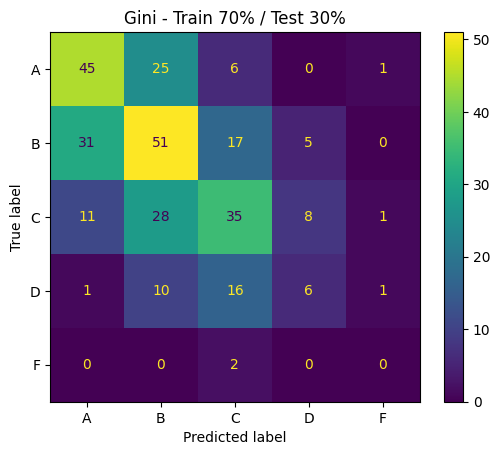

Criterion: Entropy
Training: 90 %
Testing: 10 %
Confusion Matrix:
[[14  6  0  0  0]
 [13 15 10  1  0]
 [ 1  7 15  3  1]
 [ 1  6  5  0  1]
 [ 0  1  0  0  0]]


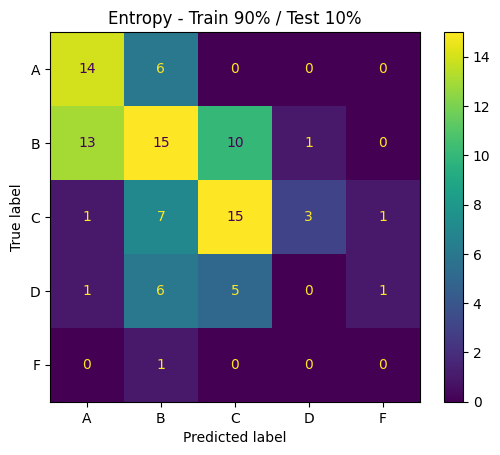

Criterion: Entropy
Training: 80 %
Testing: 20 %
Confusion Matrix:
[[24 17  4  2  0]
 [14 35 20  3  1]
 [ 4 19 22  9  1]
 [ 5  7  7  4  0]
 [ 0  1  0  1  0]]


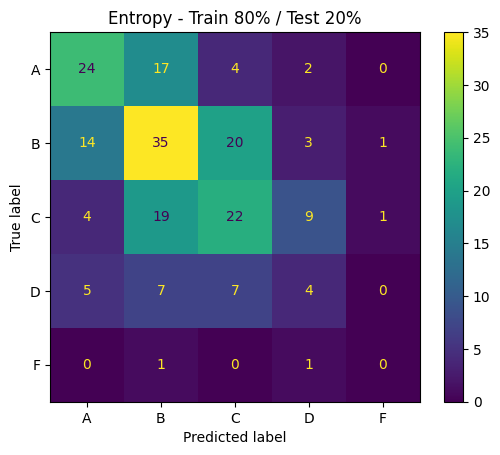

Criterion: Entropy
Training: 70 %
Testing: 30 %
Confusion Matrix:
[[45 25  6  1  0]
 [28 48 25  3  0]
 [ 7 33 34  7  2]
 [ 2 11 18  2  1]
 [ 0  0  1  1  0]]


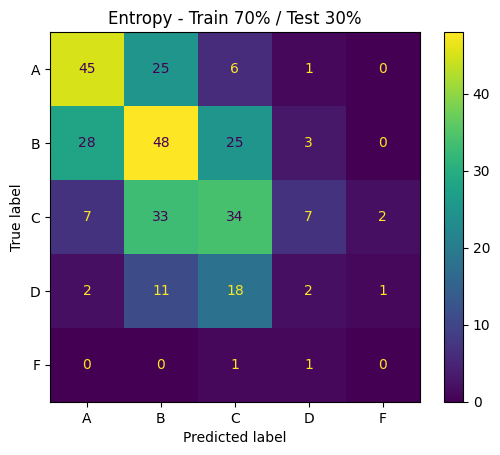

In [ ]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for criterion, models in [('Gini', gini_models),
                          ('Entropy', entropy_models)]:

    for test_size in [0.10, 0.20, 0.30]:

        X_train, X_test, y_train, y_test = splits[test_size]

        clf = models[test_size]
        y_pred = clf.predict(X_test)

        cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)

        print("Criterion:", criterion)
        print("Training:", int((1 - test_size) * 100), "%")
        print("Testing:", int(test_size * 100), "%")
        print("Confusion Matrix:")
        print(cm)

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=clf.classes_
        )

        disp.plot()
        plt.title(
            f"{criterion} - Train {int((1-test_size)*100)}% / "
            f"Test {int(test_size*100)}%"
        )
        plt.show()

### Confusion Matrix Evaluation

In this step, we used `confusion_matrix()` and `ConfusionMatrixDisplay` to evaluate and visualize the predictions of the six Decision Tree models.

Each confusion matrix compares the actual student grades with the predicted grades. The rows represent the actual grades, while the columns represent the predicted grades. Values on the main diagonal indicate correct predictions, whereas values outside the diagonal indicate incorrect predictions.

**Gini Index Results:**

* **90/10:** The model correctly classified 42 out of 100 students. Grade B had the highest number of correct predictions (20), while grade F had no correct predictions.
* **80/20:** The model correctly classified 87 out of 200 students. Grades A and B each had 30 correct predictions, while grade F had none.
* **70/30:** The model correctly classified 137 out of 300 students. Grade B had the highest number of correct predictions (51), followed by grade A (45) and grade C (35).

**Entropy Results:**

* **90/10:** The model correctly classified 44 out of 100 students. Grades B and C each had 15 correct predictions, while grades D and F had none.
* **80/20:** The model correctly classified 85 out of 200 students. Grade B had the highest number of correct predictions (35), followed by grade A (24).
* **70/30:** The model correctly classified 129 out of 300 students. Grade B had the highest number of correct predictions (48), followed by grade A (45) and grade C (34).

**Overall Observation:**

The confusion matrices show that both Gini and Entropy correctly classified some students in grades A, B, and C, but experienced difficulty classifying grades D and F.

A common classification error was confusing grades B and C. For example, in the 70/30 partition, Gini classified 28 students with an actual grade of C as B, while Entropy classified 33 students with an actual grade of C as B.

These results show that the models had difficulty distinguishing between certain grade categories, which is consistent with the relatively low accuracy values.


# 6.2 Clustering – K-Means Implementation

In [7]:
print(df.shape)
for column in df.columns:
    print(column)

(1000, 13)
student_id
gender
study_time_hours
attendance_percent
sleep_hours
parental_education
internet_access
extracurricular_activities
part_time_job
previous_grade
final_exam_score
final_grade
study_time_category


The dataset contains 1,000 student records and 13 columns. The available columns were examined to understand the dataset structure and identify the relevant features for the clustering process.

In [9]:
features = [
    'study_time_hours',
    'attendance_percent',
    'sleep_hours',
    'previous_grade',
    'final_exam_score'
]

X = df[features]

print(X.head())

   study_time_hours  attendance_percent  sleep_hours  previous_grade  \
0          0.460526            0.955752     0.485294        0.663755   
1          0.763158            1.000000     0.367647        0.643377   
2          0.578947            0.674779     0.691176        0.832606   
3          0.276316            0.502212     0.705882        0.783115   
4          0.223684            0.769912     0.205882        0.443959   

   final_exam_score  
0          1.000000  
1          1.000000  
2          0.949248  
3          0.695489  
4          0.404135  


Five numerical features were selected for the K-Means algorithm: study time, attendance percentage, sleep hours, previous grade, and final exam score. The student_id column was excluded because it is only an identifier and does not provide meaningful information for grouping students. The selected features were stored in X to be used as input for the clustering algorithm.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=5)

labels = kmeans.fit_predict(X)

wcss = kmeans.inertia_
silhouette = silhouette_score(X, labels)

print("K = 5")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)

K = 5
WCSS: 101.15435049617786
Silhouette Score: 0.15820590261521641


In this experiment, K-Means was applied using five clusters. The algorithm assigned each student to one of the five clusters based on the selected numerical features. WCSS and Silhouette Score were calculated to evaluate the clustering results.

In [14]:
kmeans = KMeans(n_clusters=4)

labels = kmeans.fit_predict(X)

wcss = kmeans.inertia_
silhouette = silhouette_score(X, labels)

print("K = 4")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)

K = 4
WCSS: 108.80940359578442
Silhouette Score: 0.17470752530816255


In this experiment, K-Means was applied using four clusters with the same selected features. WCSS and Silhouette Score were calculated to measure cluster compactness and separation. The results were compared with the other K values.

In [15]:
kmeans = KMeans(n_clusters=3)

labels = kmeans.fit_predict(X)

wcss = kmeans.inertia_
silhouette = silhouette_score(X, labels)

print("K = 3")
print("WCSS:", wcss)
print("Silhouette Score:", silhouette)

K = 3
WCSS: 119.67304807969717
Silhouette Score: 0.1869372042266712


In this experiment, K-Means was applied using three clusters. The same numerical features were used to ensure a fair comparison between the experiments. WCSS and Silhouette Score were calculated to evaluate the clustering quality.

### Comparison of K-Means Results

In [18]:
comparison = pd.DataFrame({
    'K': [3, 4, 5],
    'WCSS': [119.673048, 108.809404, 101.154350],
    'Silhouette Score': [0.186937, 0.174708, 0.158206]
})

print(comparison)

   K        WCSS  Silhouette Score
0  3  119.673048          0.186937
1  4  108.809404          0.174708
2  5  101.154350          0.158206


**K-Means Clustering Description**

K-Means was applied using three different numbers of clusters: K = 3, K = 4, and K = 5, based on five selected numerical features.

The results show that WCSS decreases as the number of clusters increases.

K = 5 achieved the lowest WCSS value (101.1544), indicating more compact clusters.

However, K = 3 achieved the highest Silhouette Score (0.1869), suggesting better cluster separation among the tested values.

The Silhouette Scores are relatively low, indicating that some overlap may exist between the clusters.

The Elbow Method and Silhouette Score will help us compare the results and choose the best number of clusters (K).

### Elbow Method


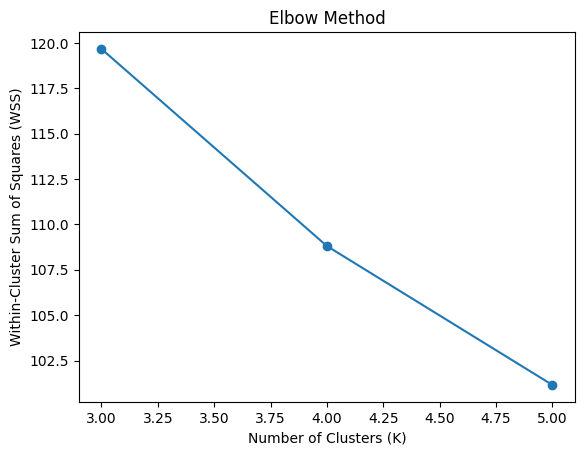

In [22]:
import matplotlib.pyplot as plt

k_values = [3, 4, 5]

wss_values = [
    119.67304807969717,
    108.80940359578442,
    101.15435049617786
]

plt.plot(k_values, wss_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WSS)')
plt.title('Elbow Method')
plt.show()

**Elbow Plot Description**

The WCSS decreases as the number of clusters increases. A noticeable change in the curve appears around K = 4, where the decrease in WCSS becomes smaller after this point. This suggests that K = 4 may be a suitable number of clusters according to the Elbow Method. However, this choice should also be compared with the Silhouette Score.

### Silhouette Score Comparison

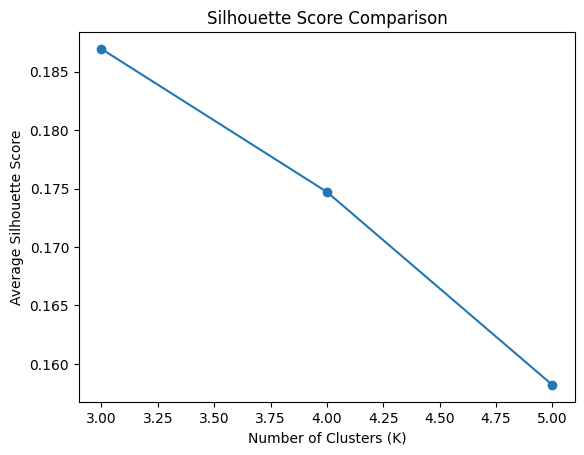

In [20]:
plt.plot(comparison['K'], comparison['Silhouette Score'], marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.show()

**Silhouette Score Plot Description**

The plot compares the Silhouette Scores for K = 3, K = 4, and K = 5. K = 3 achieved the highest score (0.1869), indicating better cluster separation compared to the other tested values. The score decreases as the number of clusters increases. This suggests that K = 3 provides the best clustering quality among the three tested values based on the Silhouette Score.

# 7. Findings and Discussion

# 8. References